# Análisis de Desempeño Comercial y Dashboard Ejecutivo en Python

Pipeline de extracción, limpieza de datos (ETL), ingeniería de características y visualización ejecutiva sobre un conjunto de **5.000 operaciones comerciales** (enero – noviembre 2026).

**Stack tecnológico:** Python · Pandas · NumPy · Matplotlib



## 1. Apuntar al archivo asignado para empezar a trabajarlo


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:

tabla = pd.read_csv('ventas_comerciales_5000.csv', sep=';')
tp = pd.DataFrame(tabla)
print(f"Registros cargados: {len(tp)}")
tp.head()

Registros cargados: 5000


,Fecha,Cliente,Producto,Cantidad,PrecioUnitario,Estado
0,2026-01-01,C0419,Teclado,4.0,50.0,Ganado
1,2026-01-01,C0554,Mouse,-1.0,25.0,Ganado
2,2026-01-01,C0097,Teclado,1.0,45.0,Ganado
3,2026-01-01,C0562,Teclado,-1.0,45.0,Ganado
4,2026-01-01,C0401,Laptop,4.0,1150.0,Ganado


## 2. Efectuar un preprocesamiento de los datos: verificar datos ausentes, duplicados e inconsistentes

In [6]:
# 1. Diagnóstico inicial
print("--- DIAGNÓSTICO INICIAL ---")
print("Valores ausentes por columna:\n", tp.isna().sum())
print(f"\nDuplicados exactos: {tp.duplicated().sum()}")
print(f"Registros con Cantidad <= 0: {(tp['Cantidad'] <= 0).sum()}")
print(f"Registros con PrecioUnitario <= 0: {(tp['PrecioUnitario'] <= 0).sum()}")

# 2. Limpieza y depuración
registros_iniciales = len(tp)

tp = tp.dropna().copy()                                      # Eliminar nulos
tp = tp.drop_duplicates().copy()                             # Eliminar duplicados exactos
tp = tp[(tp['Cantidad'] > 0) & (tp['PrecioUnitario'] > 0)]   # Filtrar inconsistencias numéricas

# Convertir a enteros limpios
tp['Cantidad'] = tp['Cantidad'].astype(int)
tp['PrecioUnitario'] = tp['PrecioUnitario'].astype(int)
tp = tp.reset_index(drop=True)

print("\n--- RESULTADO DE LIMPIEZA ---")
print(f"Registros iniciales: {registros_iniciales}")
print(f"Registros depurados válidos: {len(tp)} (Se descartaron {registros_iniciales - len(tp)} registros anómalos)")

--- DIAGNÓSTICO INICIAL ---
Valores ausentes por columna:
 Fecha             0
Cliente           0
Producto          0
Cantidad          0
PrecioUnitario    0
Estado            0
dtype: int64

Duplicados exactos: 0
Registros con Cantidad <= 0: 0
Registros con PrecioUnitario <= 0: 0

--- RESULTADO DE LIMPIEZA ---
Registros iniciales: 4827
Registros depurados válidos: 4827 (Se descartaron 0 registros anómalos)


## 3. Crear una variable que muestre el “monto_total” facturado por transacción.

In [7]:

tp['monto_total'] = tp['Cantidad'] * tp['PrecioUnitario']
tp

,Fecha,Cliente,Producto,Cantidad,PrecioUnitario,Estado,monto_total
0,2026-01-01,C0419,Teclado,4,50,Ganado,200
1,2026-01-01,C0097,Teclado,1,45,Ganado,45
2,2026-01-01,C0401,Laptop,4,1150,Ganado,4600
3,2026-01-01,C0229,Laptop,2,1100,Ganado,2200
4,2026-01-01,C0382,Laptop,3,1200,Perdido,3600
...,...,...,...,...,...,...,...
4822,2026-11-15,C0174,Mouse,2,22,Perdido,44
4823,2026-11-15,C0477,Laptop,3,1200,Ganado,3600
4824,2026-11-15,C0444,Teclado,3,45,Perdido,135
4825,2026-11-15,C0568,Mouse,3,28,Ganado,84


## 4. A partir de la variable “monto_total” crear una variable categórica llamada “Cat_facturado” que clasifique el monto total facturado como “Alto”, “Medio” y “Bajo”.

In [8]:

Q1 = tp['monto_total'].quantile(0.25)
Q2 = tp['monto_total'].quantile(0.50)

tp['Cat_facturado']=''

tp.loc[tp['monto_total'] < Q1, 'Cat_facturado'] = 'Bajo'
tp.loc[(tp['monto_total'] >= Q1)&(tp['monto_total'] < Q2), 'Cat_facturado'] = 'Medio'
tp.loc[tp['monto_total'] >= Q2, 'Cat_facturado'] = 'Alto'

tp

,Fecha,Cliente,Producto,Cantidad,PrecioUnitario,Estado,monto_total,Cat_facturado
0,2026-01-01,C0419,Teclado,4,50,Ganado,200,Alto
1,2026-01-01,C0097,Teclado,1,45,Ganado,45,Bajo
2,2026-01-01,C0401,Laptop,4,1150,Ganado,4600,Alto
3,2026-01-01,C0229,Laptop,2,1100,Ganado,2200,Alto
4,2026-01-01,C0382,Laptop,3,1200,Perdido,3600,Alto
...,...,...,...,...,...,...,...,...
4822,2026-11-15,C0174,Mouse,2,22,Perdido,44,Bajo
4823,2026-11-15,C0477,Laptop,3,1200,Ganado,3600,Alto
4824,2026-11-15,C0444,Teclado,3,45,Perdido,135,Medio
4825,2026-11-15,C0568,Mouse,3,28,Ganado,84,Bajo


## 5. Calcular: el total ganado, total perdido, el ticket promedio, la tasa de conversión y el producto más vendido.

In [9]:


ganados  = tp[tp['Estado'] == 'Ganado']
perdidos = tp[tp['Estado'] == 'Perdido']

total_ganado    = ganados['monto_total'].sum()
total_perdido   = perdidos['monto_total'].sum()
ticket_promedio = ganados['monto_total'].mean()
tasa_conversion = len(ganados) / len(tp) * 100
producto_top    = ganados.groupby('Producto')['Cantidad'].sum().idxmax()

print(f"Total ganado: ${total_ganado:,.2f}")
print(f"Total perdido: ${total_perdido:,.2f}")
print(f"Ticket promedio: ${ticket_promedio:,.2f}")
print(f"Tasa de conversión: {tasa_conversion:.1f}%")
print(f"Producto más vendido: {producto_top}")

Total ganado: $1,980,849.00
Total perdido: $1,218,135.00
Ticket promedio: $580.89
Tasa de conversión: 70.6%
Producto más vendido: Mouse


## 6. Visualizar los resultados mediante un Dashboard que contenga: 3 gráficos distintos, una tabla y un indicador.

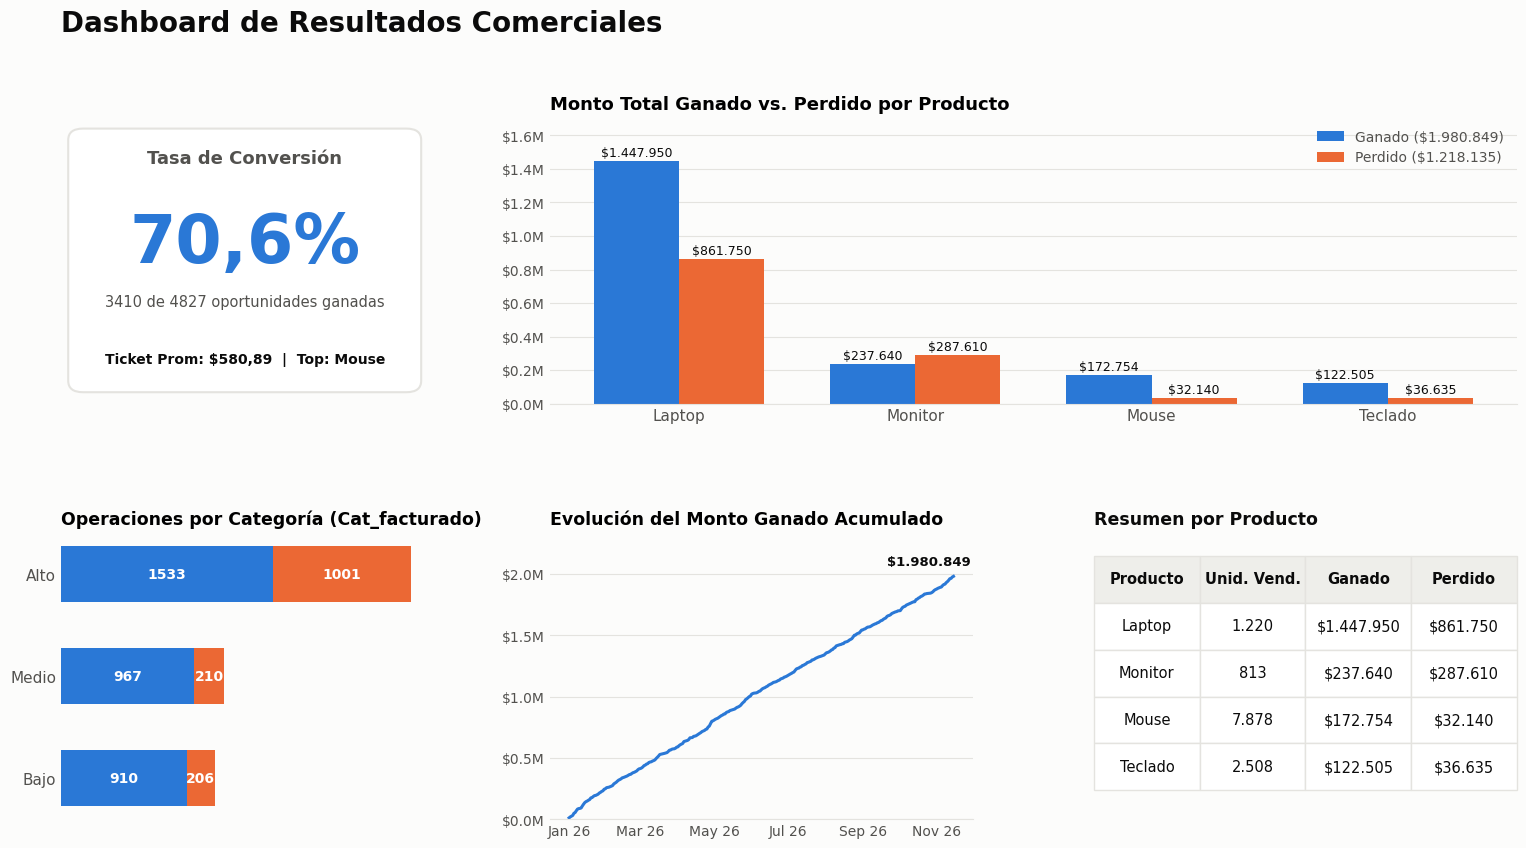

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter

# --- Función auxiliar para formato numérico argentino (miles con punto, decimales con coma) ---
def fmt_ar(valor, decimales=0, prefijo=''):
    s = f'{valor:,.{decimales}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    return f'{prefijo}{s}'

# --- 1. Métricas del Punto 5 ---
ganados  = tp[tp['Estado'] == 'Ganado']
perdidos = tp[tp['Estado'] == 'Perdido']

total_ganado    = ganados['monto_total'].sum()
total_perdido   = perdidos['monto_total'].sum()
ticket_promedio = ganados['monto_total'].mean()
tasa_conversion = len(ganados) / len(tp) * 100
producto_top    = ganados.groupby('Producto')['Cantidad'].sum().idxmax()

# --- 2. Agrupaciones para gráficos y tabla ---
monto_prod = (tp.pivot_table(index='Producto', columns='Estado', values='monto_total',
                             aggfunc='sum', fill_value=0)
                .reindex(columns=['Ganado', 'Perdido'], fill_value=0)
                .sort_values('Ganado', ascending=False))

cat_estado = (tp.pivot_table(index='Cat_facturado', columns='Estado', values='monto_total',
                             aggfunc='count', fill_value=0)
                .reindex(index=['Alto', 'Medio', 'Bajo'], columns=['Ganado', 'Perdido'], fill_value=0))

diario = (tp.assign(Fecha=pd.to_datetime(tp['Fecha']),
                    ganado=tp['monto_total'].where(tp['Estado'] == 'Ganado', 0))
            .groupby('Fecha')['ganado'].sum().cumsum())

resumen = pd.DataFrame({
    'Unidades': ganados.groupby('Producto')['Cantidad'].sum(),
    'Ganado ($)': monto_prod['Ganado'],
    'Perdido ($)': monto_prod['Perdido']
}).fillna(0).astype(int).sort_values('Ganado ($)', ascending=False)

# --- 3. Configuración visual del Dashboard ---
AZUL, NARANJA = '#2a78d6', '#eb6834'
FONDO, TEXTO, TEXTO_2, GRILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

def estilizar_eje(ax):
    ax.set_facecolor(FONDO)
    for lado in ['top', 'right', 'left']:
        ax.spines[lado].set_visible(False)
    ax.spines['bottom'].set_color(GRILLA)
    ax.tick_params(colors=TEXTO_2, length=0)
    ax.title.set_color(TEXTO)

fig = plt.figure(figsize=(16, 9), facecolor=FONDO)
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1.15, 1.15], hspace=0.45, wspace=0.3,
                      left=0.06, right=0.97, top=0.86, bottom=0.08)

fig.suptitle('Dashboard de Resultados Comerciales', x=0.06, ha='left',
             fontsize=20, fontweight='bold', color=TEXTO)

# ==============================================================================
# COMPONENTE 1: INDICADOR (KPI Principal + Métricas clave del Punto 5)
# ==============================================================================
ax_kpi = fig.add_subplot(gs[0, 0])
ax_kpi.axis('off')
ax_kpi.add_patch(FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle='round,pad=0,rounding_size=0.04',
                                transform=ax_kpi.transAxes, facecolor='white', edgecolor=GRILLA, linewidth=1.5))

ax_kpi.text(0.5, 0.84, 'Tasa de Conversión', ha='center', fontsize=13, fontweight='bold', color=TEXTO_2, transform=ax_kpi.transAxes)
ax_kpi.text(0.5, 0.56, f'{fmt_ar(tasa_conversion, 1)}%', ha='center', va='center', fontsize=48, fontweight='bold', color=AZUL, transform=ax_kpi.transAxes)
ax_kpi.text(0.5, 0.34, f'{len(ganados)} de {len(tp)} oportunidades ganadas', ha='center', fontsize=10.5, color=TEXTO_2, transform=ax_kpi.transAxes)
ax_kpi.text(0.5, 0.14, f'Ticket Prom: {fmt_ar(ticket_promedio, 2, "$")}  |  Top: {producto_top}',
            ha='center', fontsize=10, fontweight='bold', color=TEXTO, transform=ax_kpi.transAxes)

# ==============================================================================
# COMPONENTE 2: GRÁFICO 1 (Barras agrupadas: Monto Ganado vs Perdido por Producto)
# ==============================================================================
ax1 = fig.add_subplot(gs[0, 1:])
estilizar_eje(ax1)
x = range(len(monto_prod))
ancho = 0.36

b1 = ax1.bar([i - ancho/2 for i in x], monto_prod['Ganado'], ancho, color=AZUL,
             label=f'Ganado ({fmt_ar(total_ganado, 0, "$")})')
b2 = ax1.bar([i + ancho/2 for i in x], monto_prod['Perdido'], ancho, color=NARANJA,
             label=f'Perdido ({fmt_ar(total_perdido, 0, "$")})')

offset_etiqueta = monto_prod.max().max() * 0.02
for barras in (b1, b2):
    for b in barras:
        if b.get_height() > 0:
            ax1.text(b.get_x() + b.get_width()/2, b.get_height() + offset_etiqueta, fmt_ar(b.get_height(), 0, '$'),
                     ha='center', fontsize=9, color=TEXTO)

ax1.set_ylim(0, monto_prod.max().max() * 1.18)
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x/1e6:.1f}M'))
ax1.set_xticks(list(x))
ax1.set_xticklabels(monto_prod.index, fontsize=11)
ax1.yaxis.grid(True, color=GRILLA)
ax1.set_axisbelow(True)
ax1.set_title('Monto Total Ganado vs. Perdido por Producto', loc='left', fontsize=13, fontweight='bold')
ax1.legend(frameon=False, loc='upper right', labelcolor=TEXTO_2)

# ==============================================================================
# COMPONENTE 3: GRÁFICO 2 (Barras apiladas horizontales: Cat_facturado - Punto 4)
# ==============================================================================
ax2 = fig.add_subplot(gs[1, 0])
estilizar_eje(ax2)

y = range(len(cat_estado))
ax2.barh(y, cat_estado['Ganado'], color=AZUL, height=0.55, label='Ganado')
ax2.barh(y, cat_estado['Perdido'], left=cat_estado['Ganado'], color=NARANJA, height=0.55, label='Perdido')

for i, (g, p) in enumerate(zip(cat_estado['Ganado'], cat_estado['Perdido'])):
    if g > 0:
        ax2.text(g/2, i, str(g), va='center', ha='center', color='white', fontweight='bold', fontsize=10)
    if p > 0:
        ax2.text(g + p/2, i, str(p), va='center', ha='center', color='white', fontweight='bold', fontsize=10)

ax2.set_yticks(list(y))
ax2.set_yticklabels(cat_estado.index, fontsize=11)
ax2.invert_yaxis()
ax2.set_xticks([])
ax2.spines['bottom'].set_visible(False)
ax2.set_title('Operaciones por Categoría (Cat_facturado)', loc='left', fontsize=12.5, fontweight='bold')

# ==============================================================================
# COMPONENTE 4: GRÁFICO 3 (Línea de evolución: Monto Ganado Acumulado)
# ==============================================================================
ax3 = fig.add_subplot(gs[1, 1])
estilizar_eje(ax3)

ax3.plot(diario.index, diario.values, color=AZUL, linewidth=2.2)
ax3.annotate(fmt_ar(diario.iloc[-1], 0, '$'), (diario.index[-1], diario.iloc[-1]),
             xytext=(-18, 8), textcoords='offset points', ha='center', fontsize=9.5, fontweight='bold', color=TEXTO)
ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax3.yaxis.grid(True, color=GRILLA)
ax3.set_axisbelow(True)
ax3.set_ylim(0, diario.max() * 1.18)
ax3.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'${x/1e6:.1f}M'))
ax3.set_title('Evolución del Monto Ganado Acumulado', loc='left', fontsize=12.5, fontweight='bold')

# ==============================================================================
# COMPONENTE 5: TABLA (Resumen por Producto)
# ==============================================================================
ax_tab = fig.add_subplot(gs[1, 2])
ax_tab.axis('off')
ax_tab.set_title('Resumen por Producto', loc='left', fontsize=12.5, fontweight='bold', color=TEXTO)

filas_tabla = [[prod, fmt_ar(row['Unidades']), fmt_ar(row['Ganado ($)'], 0, '$'), fmt_ar(row['Perdido ($)'], 0, '$')]
               for prod, row in resumen.iterrows()]

tabla = ax_tab.table(cellText=filas_tabla,
                     colLabels=['Producto', 'Unid. Vend.', 'Ganado', 'Perdido'],
                     cellLoc='center', loc='upper center', bbox=[0, 0.1, 1, 0.82])

tabla.auto_set_font_size(False)
tabla.set_fontsize(10.5)
for (fila, col), celda in tabla.get_celld().items():
    celda.set_edgecolor(GRILLA)
    if fila == 0:
        celda.set_facecolor('#eeeeea')
        celda.set_text_props(fontweight='bold', color=TEXTO)
    else:
        celda.set_facecolor('white')
        celda.set_text_props(color=TEXTO)

fig.savefig('dashboard_resultados.png', dpi=300, bbox_inches='tight', facecolor=FONDO)
plt.show()

## FIN